Install the required libraries

In [ ]:
!pip install -q tensorflow opencv-python-headless matplotlib scikit-learn pillow

In [ ]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import zipfile

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
OpenCV version: 4.14.0
GPU available: True


Download the AT&T Database of Faces

In [ ]:
import urllib.request

dataset_url = (
    "https://www.cl.cam.ac.uk/Research/DTG/attarchive/"
    "pub/data/att_faces.zip"
)

zip_path = "/content/att_faces.zip"
dataset_path = "/content/att_faces"

urllib.request.urlretrieve(dataset_url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


Examine the dataset

In [ ]:
for root, dirs, files in os.walk(dataset_path):
    if dirs:
        print("Folder:", root)
        print("Subfolders:", dirs[:5])
        break

Folder: /content/att_faces
Subfolders: ['s2', 's30', 's20', 's23', 's26']


Load and preprocess the face images

In [ ]:
IMG_HEIGHT = 112
IMG_WIDTH = 92

images = []
labels = []
identity_names = []

for person_folder in sorted(os.listdir(dataset_path)):
    person_path = os.path.join(dataset_path, person_folder)

    if not os.path.isdir(person_path):
        continue

    person_images = []

    for filename in sorted(os.listdir(person_path)):
        image_path = os.path.join(person_path, filename)

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            continue

        image = cv2.resize(
            image,
            (IMG_WIDTH, IMG_HEIGHT)
        )

        image = image.astype("float32") / 255.0

        person_images.append(image)

    if person_images:
        identity_names.append(person_folder)
        identity_label = len(identity_names) - 1

        for image in person_images:
            images.append(image)
            labels.append(identity_label)

X = np.array(images, dtype=np.float32)
y = np.array(labels, dtype=np.int32)

X = X[..., np.newaxis]

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of identities:", len(identity_names))
print("Images per identity:", np.bincount(y))

Images shape: (400, 112, 92, 1)
Labels shape: (400,)
Number of identities: 40
Images per identity: [10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]


Display sample images

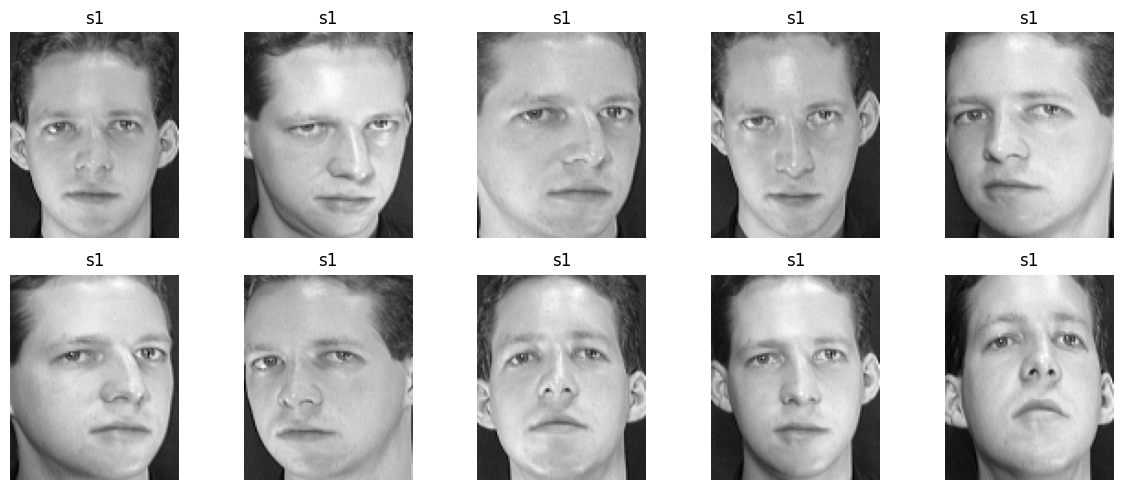

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].squeeze(), cmap="gray")
    plt.title(identity_names[y[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Split the dataset by identity

In [ ]:
from sklearn.model_selection import train_test_split

unique_labels = np.unique(y)

train_labels, test_labels = train_test_split(
    unique_labels,
    test_size=0.20,
    random_state=42
)

train_mask = np.isin(y, train_labels)
test_mask = np.isin(y, test_labels)

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

print("Training identities:", len(np.unique(y_train)))
print("Testing identities:", len(np.unique(y_test)))

assert set(np.unique(y_train)).isdisjoint(set(np.unique(y_test)))

Training images: (320, 112, 92, 1)
Testing images: (80, 112, 92, 1)
Training identities: 32
Testing identities: 8


Generate positive and negative image pairs



In [ ]:
def create_pairs(images, labels, pairs_per_class=3000, seed=42):
    rng = np.random.default_rng(seed)

    labels = np.asarray(labels)

    unique_ids = np.unique(labels)

    indices_by_id = {
        person_id: np.where(labels == person_id)[0]
        for person_id in unique_ids
    }

    # Positive pairs: same person
    valid_positive_ids = [
        person_id
        for person_id in unique_ids
        if len(indices_by_id[person_id]) >= 2
    ]

    if not valid_positive_ids:
        raise ValueError("No identities contain enough images.")

    # Negative pairs: different people
    if len(unique_ids) < 2:
        raise ValueError("At least two identities are required.")

    left_indices = []
    right_indices = []
    pair_labels = []

    for _ in range(pairs_per_class):

        # Positive pair
        person_id = rng.choice(valid_positive_ids)

        idx1, idx2 = rng.choice(
            indices_by_id[person_id],
            size=2,
            replace=False
        )

        left_indices.append(idx1)
        right_indices.append(idx2)
        pair_labels.append(1)

        # Negative pair
        person1, person2 = rng.choice(
            unique_ids,
            size=2,
            replace=False
        )

        idx1 = rng.choice(indices_by_id[person1])
        idx2 = rng.choice(indices_by_id[person2])

        left_indices.append(idx1)
        right_indices.append(idx2)
        pair_labels.append(0)

    left_indices = np.array(left_indices)
    right_indices = np.array(right_indices)
    pair_labels = np.array(pair_labels, dtype=np.float32)

    # Shuffle all pairs
    order = rng.permutation(len(pair_labels))

    left_indices = left_indices[order]
    right_indices = right_indices[order]
    pair_labels = pair_labels[order]

    return (
        images[left_indices],
        images[right_indices],
        pair_labels
    )


X1_train, X2_train, pair_y_train = create_pairs(
    X_train, y_train, pairs_per_class=3000
)

X1_test, X2_test, pair_y_test = create_pairs(
    X_test, y_test, pairs_per_class=500, seed=123
)

print("Training pairs:", len(pair_y_train))
print("Testing pairs:", len(pair_y_test))

print("Positive training pairs:", np.sum(pair_y_train == 1))
print("Negative training pairs:", np.sum(pair_y_train == 0))

Training pairs: 6000
Testing pairs: 1000
Positive training pairs: 3000
Negative training pairs: 3000


Display positive and negative pairs

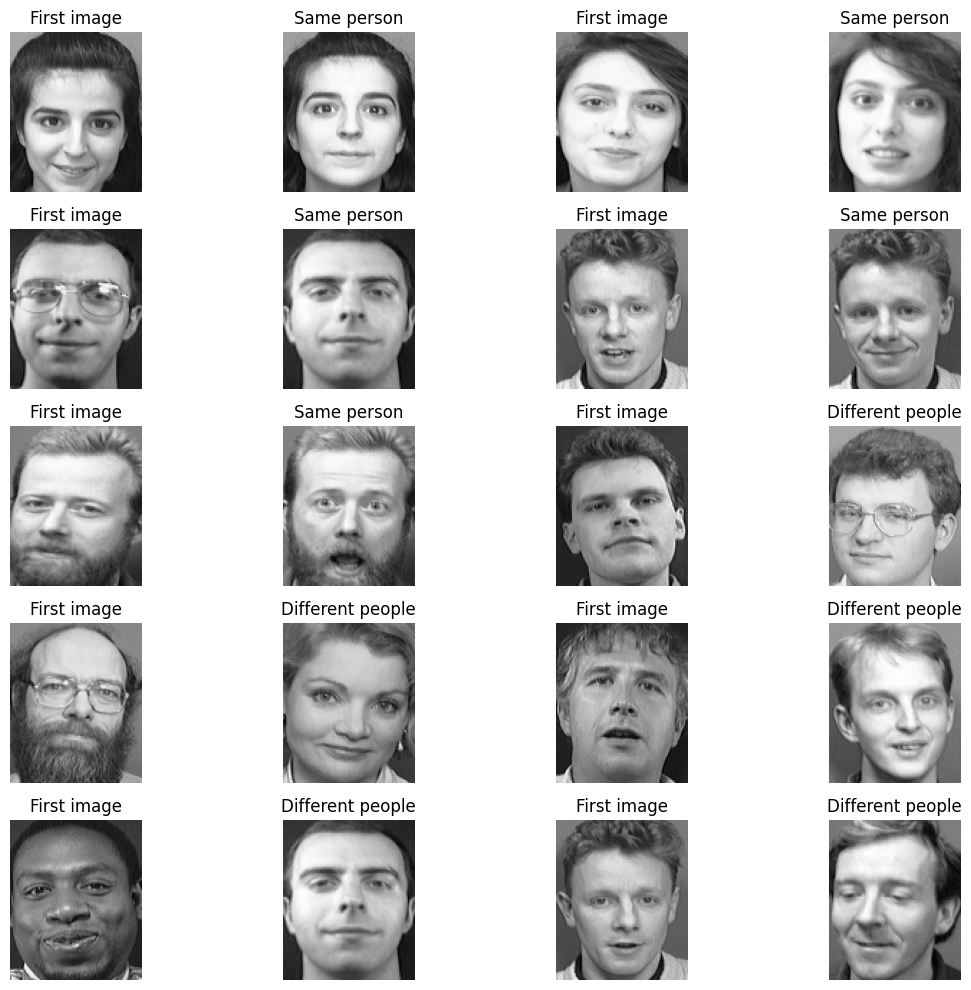

In [ ]:
def display_pairs(left_images, right_images, pair_labels, count=10):

    indices = np.arange(len(pair_labels))

    positive_indices = indices[pair_labels == 1][:5]
    negative_indices = indices[pair_labels == 0][:5]

    selected = np.concatenate([
        positive_indices,
        negative_indices
    ])

    plt.figure(figsize=(12, 10))

    for position, idx in enumerate(selected):

        plt.subplot(5, 4, position * 2 + 1)

        plt.imshow(left_images[idx].squeeze(), cmap="gray")
        plt.title("First image")
        plt.axis("off")

        plt.subplot(5, 4, position * 2 + 2)

        plt.imshow(right_images[idx].squeeze(), cmap="gray")

        label = int(pair_labels[idx])

        plt.title(
            "Same person" if label == 1 else "Different people"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


display_pairs(
    X1_train,
    X2_train,
    pair_y_train
)

Create the shared CNN feature extractor

In [ ]:
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

def create_shared_network():

    model = Sequential([
        Input(shape=(112, 92, 1)),

        Conv2D(
            64,
            kernel_size=(3, 3),
            activation="relu"
        ),

        MaxPooling2D(),

        Conv2D(
            64,
            kernel_size=(3, 3),
            activation="relu"
        ),

        Flatten(),

        Dense(
            128,
            activation="sigmoid"
        )
    ], name="shared_cnn")

    return model


shared_network = create_shared_network()

shared_network.summary()

Model: "shared_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 110, 90, 64)    │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 55, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 53, 43, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 145856)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    18,669,696 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,707,264 (71.36 MB)

 Trainable params: 18,707,264 (71.36 MB)

 Non-trainable params: 0 (0.00 B)

Extract a feature vector

In [ ]:
sample_face = X_train[:1]

feature_vector = shared_network.predict(
    sample_face,
    verbose=0
)

print("Feature vector shape:", feature_vector.shape)
print("Feature vector:")
print(feature_vector)

Feature vector shape: (1, 128)
Feature vector:
[[0.46200958 0.49264398 0.5293697  0.48437133 0.49300653 0.51379836
  0.5027964  0.49879378 0.49141297 0.4876635  0.52356344 0.47007012
  0.48989183 0.4928312  0.5251192  0.5285567  0.48614055 0.526498
  0.52076954 0.4842549  0.48055723 0.5049101  0.4982367  0.47754854
  0.5118565  0.50005406 0.50701594 0.49870625 0.46921882 0.5128286
  0.5011495  0.48498887 0.513469   0.4933468  0.5118423  0.4521109
  0.45523876 0.49158484 0.48320037 0.54288733 0.48052895 0.4625117
  0.50384456 0.49683335 0.50364935 0.51752204 0.5445941  0.4748452
  0.512526   0.53393304 0.48823643 0.46262413 0.4805627  0.48224348
  0.4498386  0.49364173 0.48168275 0.5183933  0.47885987 0.5310926
  0.44710696 0.48399717 0.48904273 0.506022   0.5074154  0.5026542
  0.4907382  0.5101608  0.50968224 0.49117243 0.5031791  0.4970492
  0.50103855 0.5093262  0.51140153 0.51474124 0.52515733 0.51041865
  0.48714417 0.5150947  0.49200907 0.51130027 0.53085774 0.51222533
  0.505854

Build the Siamese Neural Network

In [ ]:
from tensorflow.keras.layers import Lambda
import tensorflow.keras.backend as K


def euclidean_distance(vectors):

    vector_a, vector_b = vectors

    squared_difference = K.square(vector_a - vector_b)

    distance = K.sqrt(
        K.maximum(
            K.sum(squared_difference, axis=1, keepdims=True),
            K.epsilon()
        )
    )

    return distance


input_a = Input(
    shape=(112, 92, 1),
    name="input_face_1"
)

input_b = Input(
    shape=(112, 92, 1),
    name="input_face_2"
)

# Both branches use the same CNN
embedding_a = shared_network(input_a)
embedding_b = shared_network(input_b)

distance = Lambda(
    euclidean_distance,
    name="euclidean_distance"
)([embedding_a, embedding_b])

siamese_model = Model(
    inputs=[input_a, input_b],
    outputs=distance,
    name="siamese_face_recognition"
)

siamese_model.summary()

Model: "siamese_face_recognition"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_face_1        │ (None, 112, 92,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_face_2        │ (None, 112, 92,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_cnn          │ (None, 128)       │ 18,707,264 │ input_face_1[0][… │
│ (Sequential)        │                   │            │ input_face_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ euclidean_distance  │ (None, 1)         │          0 │ shared_cnn[0][0], │
│ (Lambda)            │                   │            │ shared_cnn[1][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,707,264 (71.36 MB)

 Trainable params: 18,707,264 (71.36 MB)

 Non-trainable params: 0 (0.00 B)

Test the network before training

In [ ]:
test_distance = siamese_model.predict(
    [X1_train[:5], X2_train[:5]],
    verbose=0
)

print("Distance scores:")
print(test_distance.flatten())

Distance scores:
[0.09325824 0.07279155 0.06987403 0.06859028 0.08363646]


Implement contrastive loss

In [ ]:
MARGIN = 1.0


def contrastive_loss(y_true, y_pred):

    y_true = K.cast(y_true, y_pred.dtype)

    positive_loss = y_true * K.square(y_pred)

    negative_loss = (
        (1.0 - y_true)
        * K.square(
            K.maximum(MARGIN - y_pred, 0.0)
        )
    )

    return K.mean(positive_loss + negative_loss)

Custom accuracy function

In [ ]:
def accuracy(y_true, y_pred):

    y_true = K.cast(y_true, y_pred.dtype)

    predicted_same = K.cast(
        y_pred < 0.5,
        y_true.dtype
    )

    return K.mean(
        K.cast(
            K.equal(y_true, predicted_same),
            K.floatx()
        )
    )

Compile the Siamese Neural Network

In [ ]:
from tensorflow.keras.optimizers import Adam

siamese_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=contrastive_loss,
    metrics=[accuracy]
)

print("Siamese Neural Network compiled successfully!")

Siamese Neural Network compiled successfully!


Train the model

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = siamese_model.fit(
    [X1_train, X2_train],
    pair_y_train,

    validation_split=0.2,

    epochs=10,
    batch_size=128,

    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 21s 373ms/step - accuracy: 0.5073 - loss: 0.0944 - val_accuracy: 0.5072 - val_loss: 0.0342
Epoch 2/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 0.5039 - loss: 0.0205 - val_accuracy: 0.5077 - val_loss: 0.0136
Epoch 3/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 113ms/step - accuracy: 0.5039 - loss: 0.0064 - val_accuracy: 0.5073 - val_loss: 0.0037
Epoch 4/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.5035 - loss: 0.0023 - val_accuracy: 0.5073 - val_loss: 0.0023
Epoch 5/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - accuracy: 0.5046 - loss: 0.0020 - val_accuracy: 0.5073 - val_loss: 0.0015
Epoch 6/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - accuracy: 0.5054 - loss: 7.3985e-04 - val_accuracy: 0.5073 - val_loss: 4.6812e-04
Epoch 7/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 0.5049 - loss: 1.8967e-04 - val_accuracy: 0.5073 - val_loss: 1.7790e-04
Epoch 8/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 118ms/step - accuracy: 0.5066 - loss: 1.3793e-

Plot training loss and accuracy

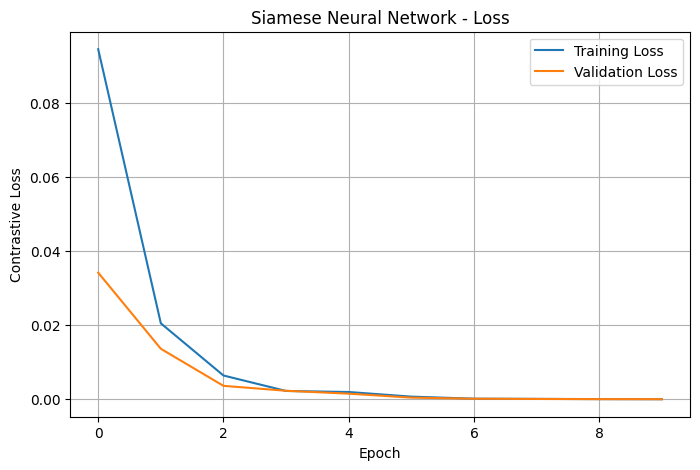

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Contrastive Loss")
plt.title("Siamese Neural Network - Loss")

plt.legend()
plt.grid(True)
plt.show()

Accuracy graph

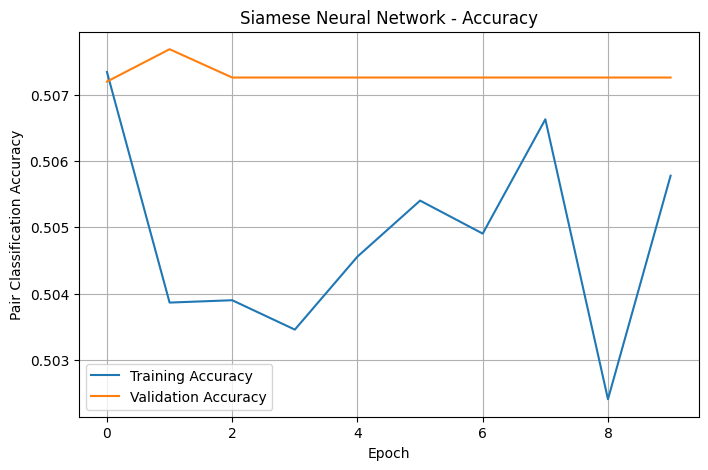

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Pair Classification Accuracy")
plt.title("Siamese Neural Network - Accuracy")

plt.legend()
plt.grid(True)
plt.show()

Evaluate the trained model

In [ ]:
test_loss, test_accuracy = siamese_model.evaluate(
    [X1_test, X2_test],
    pair_y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Pair Accuracy:", test_accuracy)

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.5123 - loss: 0.2213
Test Loss: 0.22131553292274475
Test Pair Accuracy: 0.51226806640625


Generate distance predictions

In [ ]:
test_distances = siamese_model.predict(
    [X1_test, X2_test],
    verbose=0
).flatten()

print("First 10 predicted distances:")
print(test_distances[:10])

print("First 10 actual pair labels:")
print(pair_y_test[:10].astype(int))

First 10 predicted distances:
[0.35510606 1.5621625  1.6035571  2.084103   1.7252312  1.7706345
 0.10054638 0.4273566  0.28685874 0.10054638]
First 10 actual pair labels:
[1 0 0 0 0 0 1 1 1 1]


Evaluate multiple thresholds

In [ ]:
from sklearn.metrics import accuracy_score

thresholds = np.linspace(0.05, 1.0, 20)

for threshold in thresholds:

    predictions = (
        test_distances < threshold
    ).astype(int)

    score = accuracy_score(
        pair_y_test.astype(int),
        predictions
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Accuracy: {score:.4f}"
    )

Threshold: 0.05 | Accuracy: 0.5090
Threshold: 0.10 | Accuracy: 0.5330
Threshold: 0.15 | Accuracy: 0.5520
Threshold: 0.20 | Accuracy: 0.5790
Threshold: 0.25 | Accuracy: 0.5920
Threshold: 0.30 | Accuracy: 0.6200
Threshold: 0.35 | Accuracy: 0.6470
Threshold: 0.40 | Accuracy: 0.6830
Threshold: 0.45 | Accuracy: 0.7080
Threshold: 0.50 | Accuracy: 0.7340
Threshold: 0.55 | Accuracy: 0.7420
Threshold: 0.60 | Accuracy: 0.7760
Threshold: 0.65 | Accuracy: 0.7900
Threshold: 0.70 | Accuracy: 0.7960
Threshold: 0.75 | Accuracy: 0.8190
Threshold: 0.80 | Accuracy: 0.8430
Threshold: 0.85 | Accuracy: 0.8610
Threshold: 0.90 | Accuracy: 0.8740
Threshold: 0.95 | Accuracy: 0.8860
Threshold: 1.00 | Accuracy: 0.8930


Save the trained model

In [ ]:
model_path = "/content/siamese_nn.h5"

siamese_model.save(model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: /content/siamese_nn.h5


Download the model

In [ ]:
from google.colab import files

files.download("/content/siamese_nn.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Save that model separately:

In [ ]:
shared_network.save("/content/face_embedding_model.keras")

files.download("/content/face_embedding_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Develop the face detection module

Load the face detector

In [ ]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

if face_cascade.empty():
    raise RuntimeError("Could not load Haar Cascade detector.")

print("Haar Cascade face detector loaded successfully!")

Haar Cascade face detector loaded successfully!


Create a face detection function

In [ ]:
def detect_faces(image):

    if image is None:
        return []

    if len(image.shape) == 3:
        gray = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2GRAY
        )
    else:
        gray = image

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    return faces

Crop and preprocess a detected face

In [ ]:
def preprocess_face(face_image):

    if len(face_image.shape) == 3:
        face_image = cv2.cvtColor(
            face_image,
            cv2.COLOR_BGR2GRAY
        )

    face_image = cv2.resize(
        face_image,
        (IMG_WIDTH, IMG_HEIGHT)
    )

    face_image = (
        face_image.astype("float32") / 255.0
    )

    face_image = np.expand_dims(
        face_image,
        axis=-1
    )

    return face_image

Upload an image and test face detection

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 20251226_161527.jpg to 20251226_161527.jpg


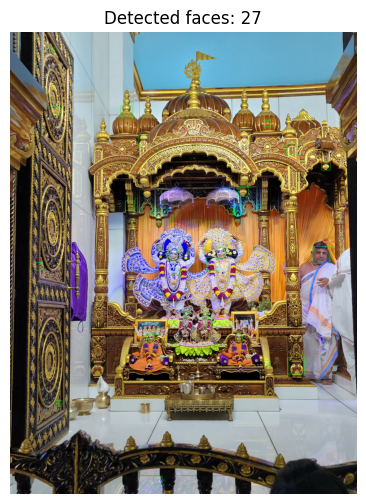

In [ ]:
uploaded_filename = next(iter(uploaded.keys()))

image = cv2.imread(uploaded_filename)

if image is None:
    raise ValueError("Could not read the uploaded image.")

faces = detect_faces(image)

display_image = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

for (x, y_box, w, h) in faces:

    cv2.rectangle(
        display_image,
        (x, y_box),
        (x + w, y_box + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 6))

plt.imshow(display_image)
plt.title(f"Detected faces: {len(faces)}")
plt.axis("off")

plt.show()

Extract the first detected face

Processed face shape: (112, 92, 1)


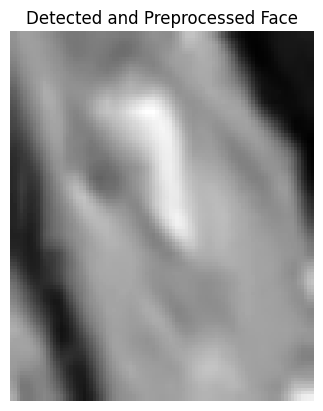

In [ ]:
if len(faces) > 0:

    x, y_box, w, h = faces[0]

    face_crop = image[
        y_box:y_box + h,
        x:x + w
    ]

    processed_face = preprocess_face(face_crop)

    print("Processed face shape:", processed_face.shape)

    plt.imshow(
        processed_face.squeeze(),
        cmap="gray"
    )

    plt.title("Detected and Preprocessed Face")
    plt.axis("off")
    plt.show()

else:
    print("No face detected. Try a clearer, front-facing image.")

Create the user registration system

In [ ]:
import json

REGISTERED_DIR = "/content/registered_users"

os.makedirs(
    REGISTERED_DIR,
    exist_ok=True
)

DATABASE_PATH = os.path.join(
    REGISTERED_DIR,
    "users.json"
)

if os.path.exists(DATABASE_PATH):

    with open(DATABASE_PATH, "r") as f:
        user_database = json.load(f)

else:
    user_database = {}

print("User database loaded.")

User database loaded.


Create the registration function

In [ ]:
def register_user(user_id, user_name, face_images):

    if user_id in user_database:
        print("This user ID is already registered.")
        return

    embeddings = []

    for face_image in face_images:

        face_image = np.asarray(
            face_image,
            dtype=np.float32
        )

        if face_image.shape == (112, 92):
            face_image = face_image[..., np.newaxis]

        if face_image.shape != (112, 92, 1):
            print("Skipping an image with an invalid shape.")
            continue

        face_batch = np.expand_dims(
            face_image,
            axis=0
        )

        embedding = shared_network.predict(
            face_batch,
            verbose=0
        )[0]

        embeddings.append(embedding.tolist())

    if not embeddings:
        print("No valid face images were provided.")
        return

    user_database[user_id] = {
        "name": user_name,
        "embeddings": embeddings
    }

    with open(DATABASE_PATH, "w") as f:
        json.dump(user_database, f)

    print(f"User {user_name} registered successfully!")

Register a face from the uploaded image

In [ ]:
if len(faces) > 0:

    x, y_box, w, h = faces[0]

    face_crop = image[
        y_box:y_box + h,
        x:x + w
    ]

    face_for_registration = preprocess_face(
        face_crop
    )

    register_user(
        user_id="USER001",
        user_name="User One",
        face_images=[face_for_registration]
    )

else:
    print("Upload an image containing a detectable face first.")

User User One registered successfully!


Display registered users

In [ ]:
if os.path.exists(DATABASE_PATH):

    with open(DATABASE_PATH, "r") as f:
        user_database = json.load(f)

    print("Registered Users")
    print("----------------")

    for user_id, details in user_database.items():

        print("User ID:", user_id)
        print("Name:", details["name"])
        print(
            "Stored embeddings:",
            len(details["embeddings"])
        )
        print()

else:
    print("No registered users found.")

Registered Users
----------------
User ID: USER001
Name: User One
Stored embeddings: 1



Implement face verification

In [ ]:
def verify_user(face_image, threshold=0.5):

    if not user_database:
        return {
            "status": "Unknown User",
            "name": None,
            "distance": None
        }

    face_image = np.asarray(
        face_image,
        dtype=np.float32
    )

    if face_image.shape == (112, 92):
        face_image = face_image[..., np.newaxis]

    if face_image.shape != (112, 92, 1):
        raise ValueError(
            "Face image must have shape (112, 92, 1)."
        )

    query_embedding = shared_network.predict(
        np.expand_dims(face_image, axis=0),
        verbose=0
    )[0]

    best_user = None
    best_distance = float("inf")

    for user_id, details in user_database.items():

        for stored_embedding in details["embeddings"]:

            stored_embedding = np.array(
                stored_embedding,
                dtype=np.float32
            )

            distance = np.linalg.norm(
                query_embedding - stored_embedding
            )

            if distance < best_distance:
                best_distance = float(distance)
                best_user = user_id

    if best_distance < threshold:

        return {
            "status": "Recognized",
            "user_id": best_user,
            "name": user_database[best_user]["name"],
            "distance": best_distance
        }

    return {
        "status": "Unknown User",
        "name": None,
        "distance": best_distance
    }

Verify an uploaded face

In [ ]:
if len(faces) > 0:

    x, y_box, w, h = faces[0]

    face_crop = image[
        y_box:y_box + h,
        x:x + w
    ]

    query_face = preprocess_face(
        face_crop
    )

    result = verify_user(
        query_face,
        threshold=0.5
    )

    print("Verification Result")
    print("-------------------")

    for key, value in result.items():
        print(f"{key}: {value}")

else:
    print("No face detected in the uploaded image.")

Verification Result
-------------------
status: Recognized
user_id: USER001
name: User One
distance: 0.0


Add a function to delete registered users

In [ ]:
def delete_user(user_id):

    if user_id not in user_database:
        print("User ID not found.")
        return

    del user_database[user_id]

    with open(DATABASE_PATH, "w") as f:
        json.dump(user_database, f)

    print("User deleted successfully.")

Test the main project functions

In [ ]:
print("TEST 1: Dataset")

assert X.ndim == 4
assert X.shape[1:] == (112, 92, 1)

print("Dataset test passed.")


print("\nTEST 2: Positive and negative pairs")

assert len(X1_train) == len(X2_train)
assert len(X1_train) == len(pair_y_train)

assert set(np.unique(pair_y_train)) == {0.0, 1.0}

print("Pair generation test passed.")


print("\nTEST 3: Feature extraction")

test_embedding = shared_network.predict(
    X_train[:1],
    verbose=0
)

assert test_embedding.shape == (1, 128)

print("Feature extraction test passed.")


print("\nTEST 4: Siamese distance")

test_distance = siamese_model.predict(
    [X1_train[:1], X2_train[:1]],
    verbose=0
)

assert test_distance.shape == (1, 1)

print("Distance calculation test passed.")


print("\nTEST 5: Model file")

assert os.path.exists(
    "/content/siamese_nn.h5"
)

print("Model saving test passed.")

TEST 1: Dataset
Dataset test passed.

TEST 2: Positive and negative pairs
Pair generation test passed.

TEST 3: Feature extraction
Feature extraction test passed.

TEST 4: Siamese distance
Distance calculation test passed.

TEST 5: Model file
Model saving test passed.


Download your project files

Download the Siamese model

In [ ]:
from google.colab import files

files.download("/content/siamese_nn.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download the embedding model

In [ ]:
files.download("/content/face_embedding_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download the registered-user database

In [ ]:
if os.path.exists(DATABASE_PATH):
    files.download(DATABASE_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>